# Plot Juno's trajectory.

In [1]:
import pandas as pd
import datetime as dt
import numpy as np 
import matplotlib.pyplot as plt 

from matplotlib.ticker import AutoMinorLocator

from JunoPy.spice import InitSpiceKernels, get_juno_position

## Get the spacecraft position for the given times.

In [2]:
start = dt.datetime(2016, 6, 25, 17, 30)
end   = dt.datetime(2019, 5, 31, 16)

time_array = pd.date_range(
        start=start, end=end, periods=10000).to_pydatetime().tolist()

InitSpiceKernels()
position, _ = get_juno_position(time_array)

## Plot Position

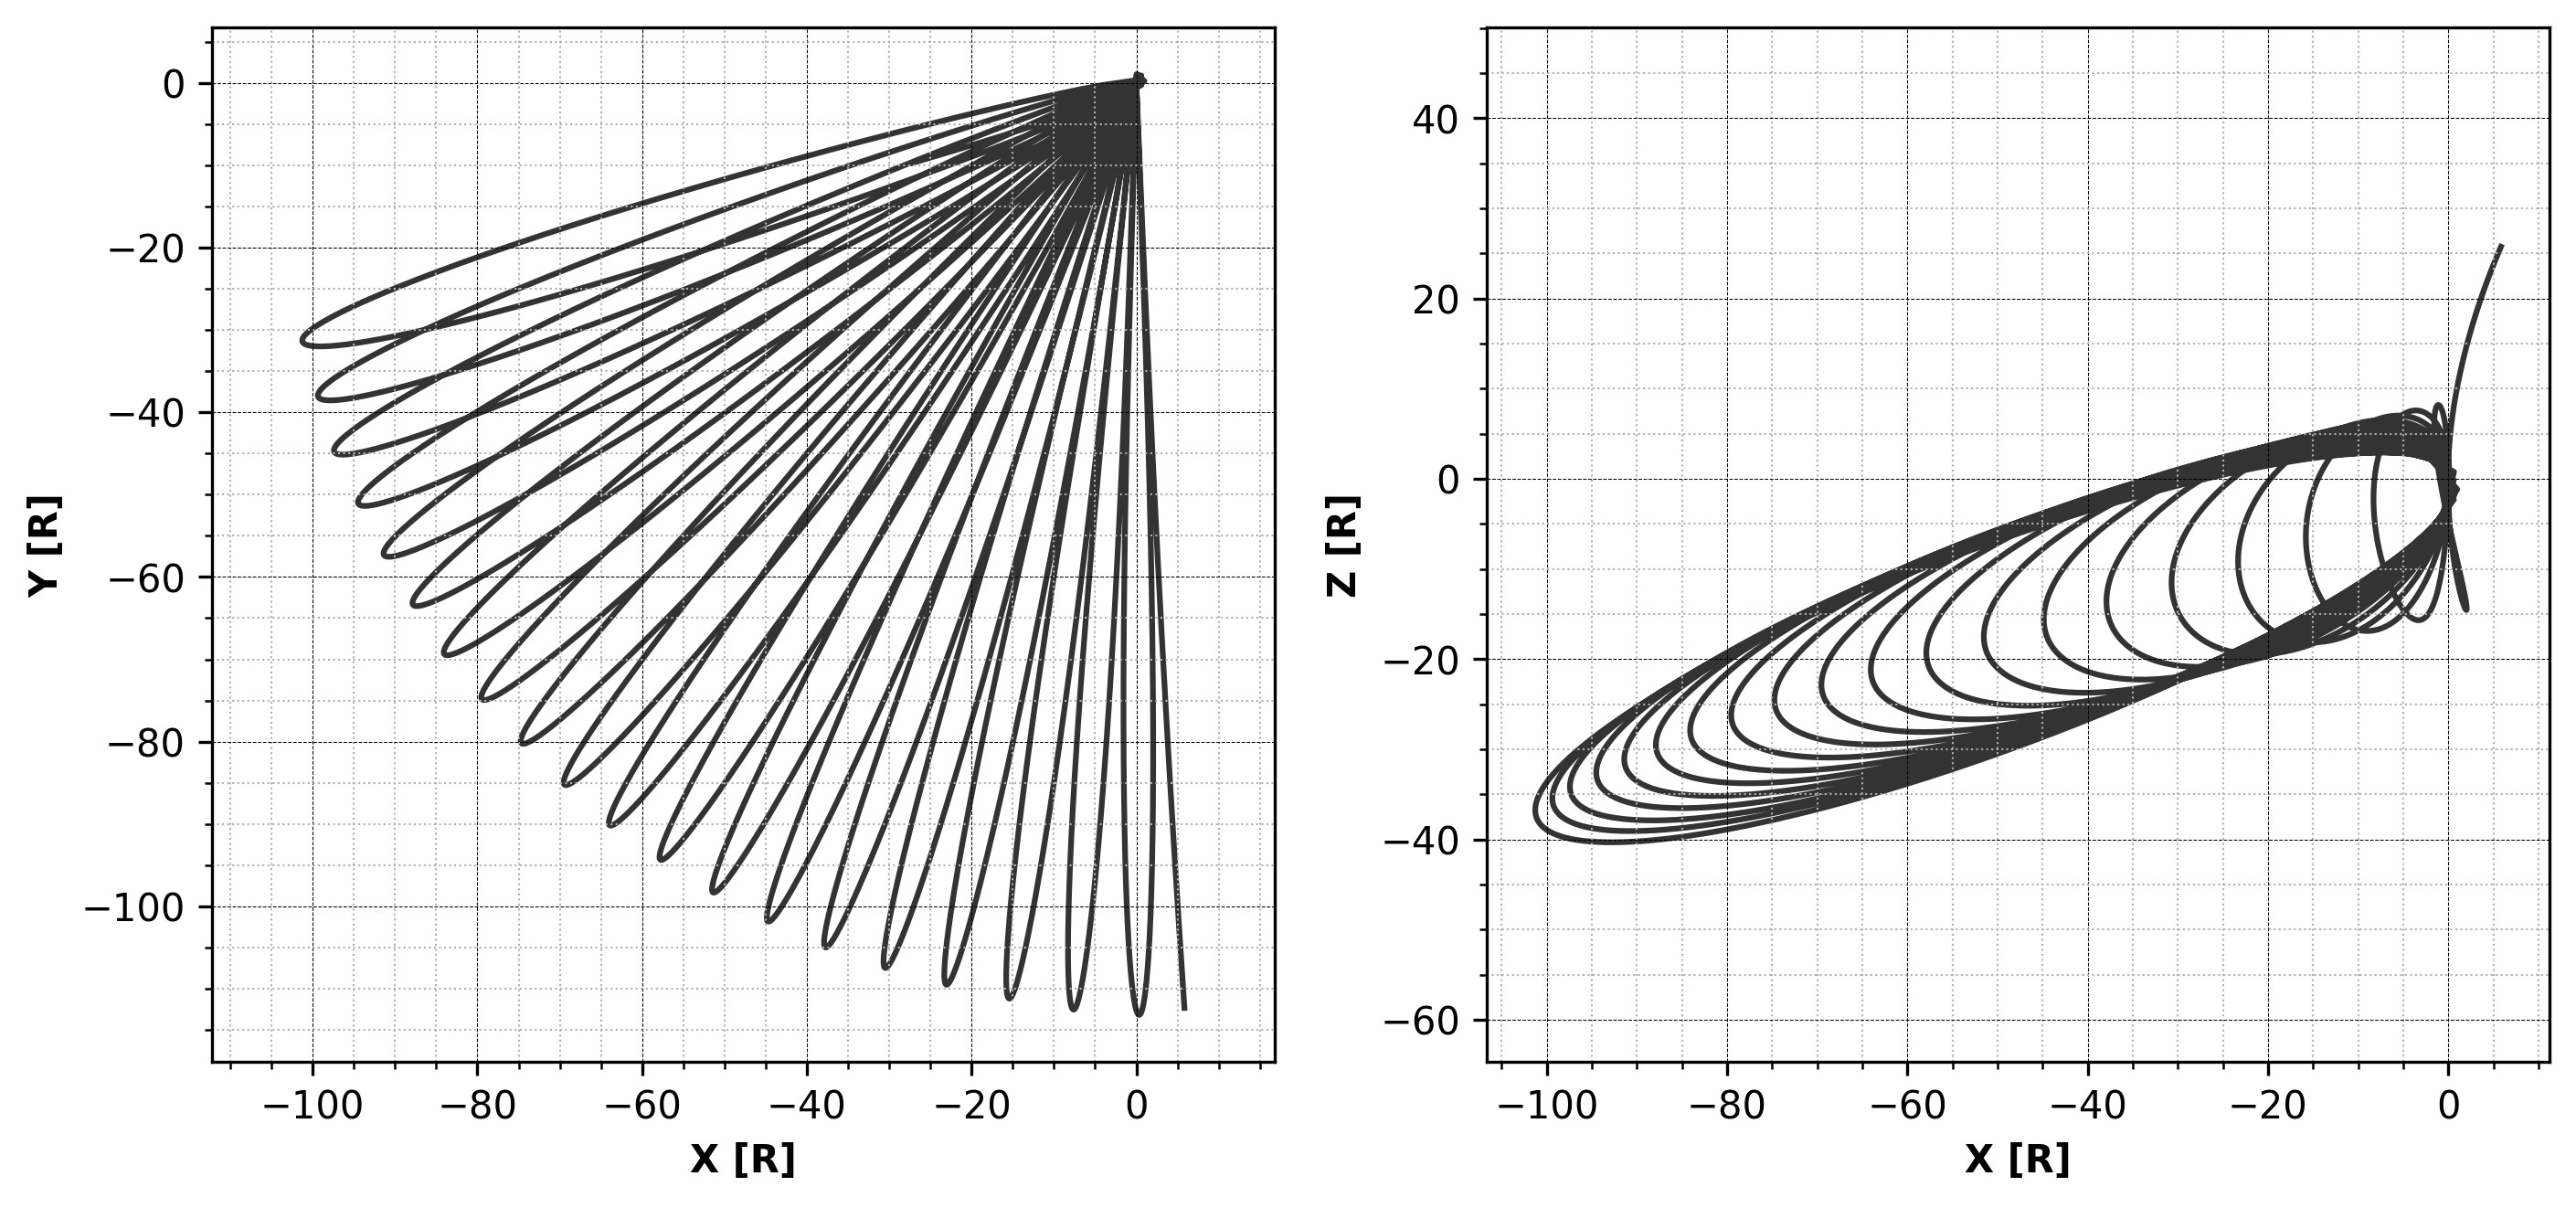

In [3]:
fig = plt.figure(figsize=(11, 5), constrained_layout=False, dpi=300)

ax1 = plt.subplot(121)
ax2 = plt.subplot(122)
    
ax1.plot(position[:, 0], position[:, 1], color=[0.2, 0.2, 0.2], zorder=1)
ax2.plot(position[:, 0], position[:, 2], color=[0.2, 0.2, 0.2], zorder=1)

ax1.xaxis.set_minor_locator(AutoMinorLocator())
ax1.yaxis.set_minor_locator(AutoMinorLocator())
ax2.xaxis.set_minor_locator(AutoMinorLocator())
ax2.yaxis.set_minor_locator(AutoMinorLocator())
ax1.grid('on', which='minor', lw=0.5, ls='dotted')
ax1.grid(color='k', ls='dashed', lw=0.25)
ax2.grid('on', which='minor', lw=0.5, ls='dotted')
ax2.grid(color='k', ls='dashed', lw=0.25)

ax1.set_xlabel('X [R]', weight='bold')
ax1.set_ylabel('Y [R]', weight='bold')
ax2.set_xlabel('X [R]', weight='bold')
ax2.set_ylabel('Z [R]', weight='bold')

ax1.set_aspect('equal', adjustable="datalim")
ax2.set_aspect('equal', adjustable="datalim")
# plt.subplots_adjust(hspace=0)

## Read the MVA epochs file and get the spacecraft position for the corresponding time

In [4]:
def read_csv_file():
    times = []
    durations = []
    with open('mva_epochs.csv', 'r') as f:
        f.readline()
        for line in f:
            times.append(dt.datetime.strptime(line.split(',')[0], '%Y-%jT%H:%M:%S'))
            durations.append(float(line.split(',')[-1]))
    return times, durations
            
times_mva, durations = read_csv_file()
position_mva, _ = get_juno_position(times_mva)

In [5]:
sc1 = ax1.scatter(position_mva[:, 0], position_mva[:, 1], c=durations, zorder=2, marker='o', cmap='jet')
sc2 = ax2.scatter(position_mva[:, 0], position_mva[:, 2], c=durations, zorder=2, marker='o', cmap='jet')

In [6]:
# cbar1 = fig.colorbar(sc1, ax=ax1);
# cbar2 = fig.colorbar(sc2, ax=ax2);
# cbar1.set_label('Duration (s)')
# cbar2.set_label('Duration (s)')
cbar2 = fig.colorbar(sc2);
cbar2.set_label('Duration (s)')
plt.subplots_adjust(wspace=0.3)
fig.savefig('TrajectoryLocationofEvent.png')

<Figure size 432x288 with 0 Axes>